<a href="https://colab.research.google.com/github/mjk022/portfolio/blob/main/%EA%B8%B0%EA%B0%84%EB%B3%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 18 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (8,351 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 120895 files and dire

In [ ]:
import matplotlib.pyplot as plt

# matplotlib 폰트설정
plt.rc('font', family='NanumGothic') # For Windows
print(plt.rcParams['font.family'])

%matplotlib inline

['NanumGothic']


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt #시각화에 사용하는 것 이거하고 seaborn 두개 있다.
import folium
import re
import openpyxl
#!pip install tabulate
from tabulate import tabulate
import math
! pip install haversine
from haversine import haversine
from scipy import stats
from sklearn.cluster import KMeans
from sklearn import preprocessing
import warnings
warnings.filterwarnings('ignore')
import geopandas as gpd
import seaborn as sns
## 모델 적합용 데이터 전처리 관련 라이브러리
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.impute import KNNImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor#다중공선성
## 모델 생성 및 성능평가 라이브러리
from xgboost import XGBClassifier
import xgboost as xgb
from xgboost import plot_importance ## Feature Importance를 불러오기 위함
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')
## DNN 관련 라이브러리
from tensorflow.keras.layers import Dense,SimpleRNN,LSTM,Dropout
from tensorflow.keras import models
from tensorflow.keras import layers,optimizers
import os
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping
from tensorflow.keras.models import load_model
import keras
from sklearn import svm
from sklearn import metrics

## -기간별

In [ ]:
#추가 수집데이터 추가와 위경도 null값처리한 데이터를 이용한 EDA
all_data = pd.read_csv('/content/gdrive/MyDrive/2023 빅콘테스트/데이터/all_data(null).csv')
all_data.head()

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,202201,1111010100100030100,11110101,A03,4,0.47,19.76,LH,89.26,NaN,934.011841,126.966923,37.592027,15346.7477,0
1,202201,1111010100100480000,11110101,A01,2,1.40,39.13,LH,59.29,59.42,386.339233,126.969415,37.587042,15346.7477,0
2,202201,1111010100100590001,11110101,A11,3,0.34,27.26,LH,53.20,48.86,6.136597,126.969893,37.586417,15346.7477,0
3,202201,1111010100100590005,11110101,A03,2,0.15,21.03,LH,91.49,46.78,100.975708,126.969359,37.586218,15346.7477,0
4,202201,1111010100100690000,11110101,A01,2,1.75,23.93,LH,45.40,50.58,311.235596,126.970119,37.586430,15346.7477,0


In [ ]:
# 각 기간과 매출등급으로 묶어주기
month=all_data.groupby(['DATA_CRTR_YM', 'SLS_GRD']).size().reset_index(name='횟수')
month

,DATA_CRTR_YM,SLS_GRD,횟수
0,202201,1,9399
1,202201,2,23467
2,202201,3,28164
3,202201,4,23467
4,202201,5,9398
5,202202,1,9348
6,202202,2,23351
7,202202,3,28017
8,202202,4,23351
9,202202,5,9348


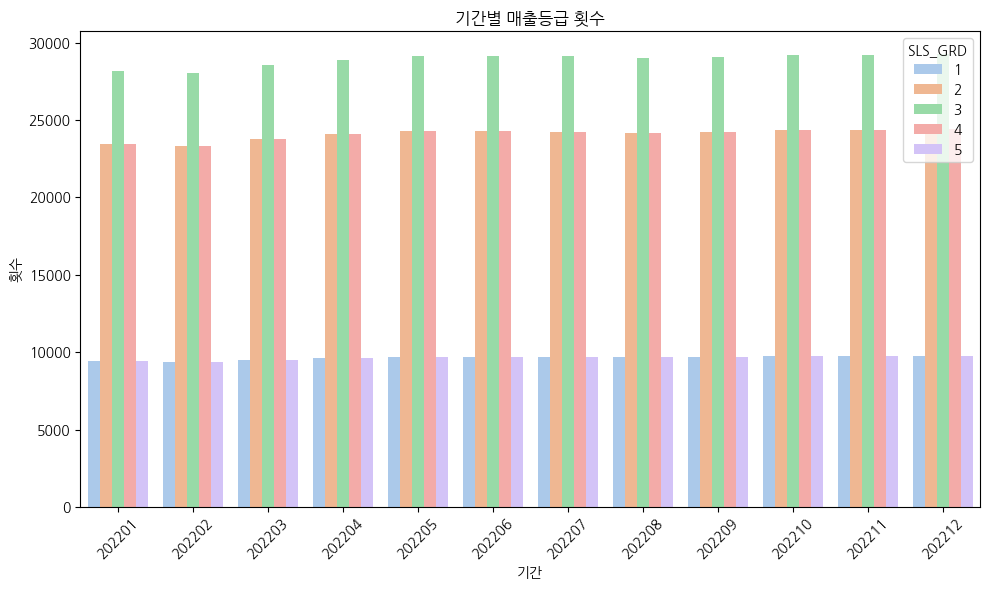

In [ ]:
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=month, x='DATA_CRTR_YM', y='횟수', hue='SLS_GRD', palette='pastel')
plt.title('기간별 매출등급 횟수')
plt.xlabel('기간')
plt.ylabel('횟수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#월별 매출등급의 분포
data = pd.pivot_table(month,                # 피벗할 데이터프레임
                     index = 'DATA_CRTR_YM',    # 행 위치에 들어갈 열
                     columns = 'SLS_GRD',    # 열 위치에 들어갈 열
                     values = '횟수')    # 데이터로 사용할 열
data

SLS_GRD,1,2,3,4,5
DATA_CRTR_YM,,,,,
202201,9399,23467,28164,23467,9398
202202,9348,23351,28017,23351,9348
202203,9520,23776,28534,23776,9519
202204,9646,24088,28906,24090,9642
202205,9720,24277,29138,24277,9719
202206,9717,24266,29118,24267,9714
202207,9713,24257,29113,24257,9712
202208,9680,24178,29011,24179,9678
202209,9701,24230,29077,24231,9699


<Axes: title={'center': '월별 매출등급 건수'}, xlabel='월별', ylabel='매출등급 건수'>

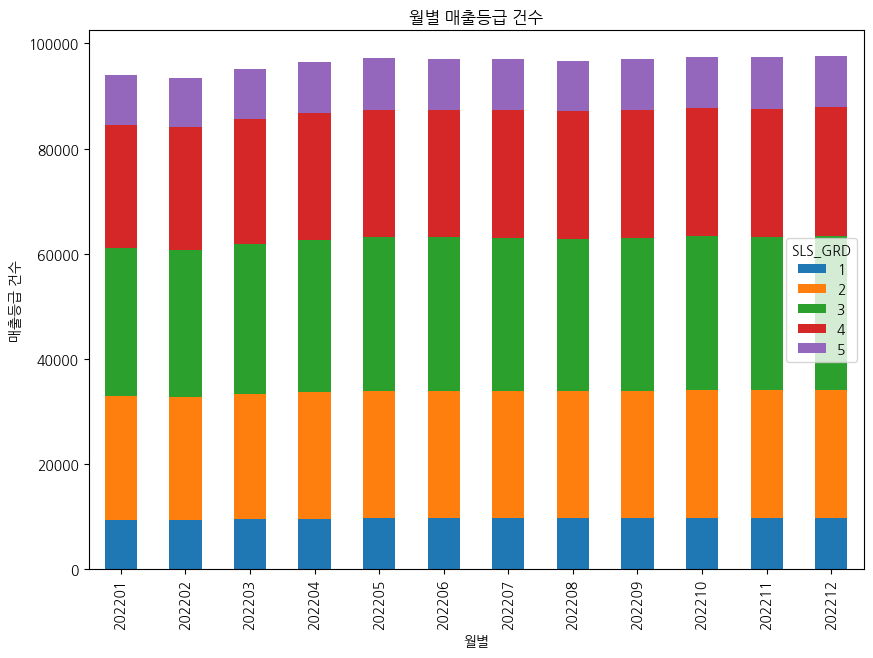

In [ ]:
data.plot.bar(stacked=True, figsize=(10,7),xlabel='월별',
               ylabel='매출등급 건수', title='월별 매출등급 건수')
#월별로 매출등급의 비율이 큰차이는 없다

In [ ]:
all_data.head()

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,202201,1111010100100030100,11110101,A03,4,0.47,19.76,LH,89.26,NaN,934.011841,126.966923,37.592027,15346.7477,0
1,202201,1111010100100480000,11110101,A01,2,1.40,39.13,LH,59.29,59.42,386.339233,126.969415,37.587042,15346.7477,0
2,202201,1111010100100590001,11110101,A11,3,0.34,27.26,LH,53.20,48.86,6.136597,126.969893,37.586417,15346.7477,0
3,202201,1111010100100590005,11110101,A03,2,0.15,21.03,LH,91.49,46.78,100.975708,126.969359,37.586218,15346.7477,0
4,202201,1111010100100690000,11110101,A01,2,1.75,23.93,LH,45.40,50.58,311.235596,126.970119,37.586430,15346.7477,0


In [ ]:
#group=all_data[['DATA_CRTR_YM',	'LT_UNQ_NO'	,'INDUSTRY_CD'	,'SLS_GRD']]
#group

In [ ]:
#2022년도에 어떤 가게들이 존재하였는지 리스트뽑기
#grouped=group.groupby(['LT_UNQ_NO', 'INDUSTRY_CD']).sum().reset_index()[['LT_UNQ_NO','INDUSTRY_CD']]
#grouped

가게별 평균 매출등급 구하기

각 (필지번호,업종)을 키로 잡았다.

In [ ]:
#해당 가게의 전체 매출등급 합을 구한다.
aa=all_data.groupby(['LT_UNQ_NO', 'INDUSTRY_CD']).sum('SLS_GRD')['SLS_GRD'].reset_index(name='매출등급합')
aa

,LT_UNQ_NO,INDUSTRY_CD,매출등급합
0,1111010100100030100,A03,44
1,1111010100100480000,A01,21
2,1111010100100590001,A11,36
3,1111010100100590005,A01,37
4,1111010100100590005,A03,25
...,...,...,...
109967,1174011000106950000,A03,42
109968,1174011000106950000,A04,36
109969,1174011000106990000,A01,47
109970,1174011000107070000,A03,39


In [ ]:
#해당 가게의 전체 운영달의 횟수를 구한다.
a=all_data.groupby(['LT_UNQ_NO', 'INDUSTRY_CD']).size().reset_index(name='횟수')
a

,LT_UNQ_NO,INDUSTRY_CD,횟수
0,1111010100100030100,A03,12
1,1111010100100480000,A01,12
2,1111010100100590001,A11,12
3,1111010100100590005,A01,11
4,1111010100100590005,A03,12
...,...,...,...
109967,1174011000106950000,A03,12
109968,1174011000106950000,A04,12
109969,1174011000106990000,A01,11
109970,1174011000107070000,A03,12


In [ ]:
#해당 가게에 매출등급의 합과 운영달의 횟수 데이터를 붙여준다.
aaa=a.merge(aa,how='left')
aaa.head()

,LT_UNQ_NO,INDUSTRY_CD,횟수,매출등급합
0,1111010100100030100,A03,12,44
1,1111010100100480000,A01,12,21
2,1111010100100590001,A11,12,36
3,1111010100100590005,A01,11,37
4,1111010100100590005,A03,12,25


In [ ]:
# 매출등급 평균 열 생성하기
aaa['매출등급 평균']=aaa['매출등급합']/aaa['횟수']
aaa.head()

,LT_UNQ_NO,INDUSTRY_CD,횟수,매출등급합,매출등급 평균
0,1111010100100030100,A03,12,44,3.666667
1,1111010100100480000,A01,12,21,1.750000
2,1111010100100590001,A11,12,36,3.000000
3,1111010100100590005,A01,11,37,3.363636
4,1111010100100590005,A03,12,25,2.083333


In [ ]:
#열순서 재배치하기
aaa=aaa[['LT_UNQ_NO','INDUSTRY_CD','매출등급 평균','매출등급합','횟수']]
aaa

,LT_UNQ_NO,INDUSTRY_CD,매출등급 평균,매출등급합,횟수
0,1111010100100030100,A03,3.666667,44,12
1,1111010100100480000,A01,1.750000,21,12
2,1111010100100590001,A11,3.000000,36,12
3,1111010100100590005,A01,3.363636,37,11
4,1111010100100590005,A03,2.083333,25,12
...,...,...,...,...,...
109967,1174011000106950000,A03,3.500000,42,12
109968,1174011000106950000,A04,3.000000,36,12
109969,1174011000106990000,A01,4.272727,47,11
109970,1174011000107070000,A03,3.250000,39,12


매출등급 평균이 2이하인 가게(매출등급이 좋은가게)

In [ ]:
a2_low=aaa[aaa['매출등급 평균']<=2]
a2_low

,LT_UNQ_NO,INDUSTRY_CD,매출등급 평균,매출등급합,횟수
1,1111010100100480000,A01,1.750000,21,12
5,1111010100100690000,A01,1.583333,19,12
9,1111010100100940001,A03,1.750000,21,12
10,1111010100100940002,A01,2.000000,24,12
25,1111010200100580001,A04,2.000000,24,12
...,...,...,...,...,...
109935,1174011000106750001,A04,2.000000,24,12
109956,1174011000106790000,A06,1.583333,19,12
109959,1174011000106790001,A11,2.000000,24,12
109960,1174011000106790002,A02,1.666667,20,12


In [ ]:
#어떤 업종이 주로 평점 2이하인지 알아보기: 비교기준을 같게 만들기 위한 작업
a2_low['INDUSTRY_CD'].value_counts().sort_index('index')

A01    7791
A02     864
A03    6501
A04     826
A05     509
A06     958
A07     375
A08    1268
A09      78
A10     115
A11    1021
A12     382
A13    1075
A14    1021
A15      87
Name: INDUSTRY_CD, dtype: int64

In [ ]:
#2022년 전체 기간에 존재하는 업종갯수
all_data['INDUSTRY_CD'].value_counts().sort_index('index')

A01    400457
A02     43621
A03    337680
A04     37287
A05     22033
A06     43390
A07     18567
A08     57529
A09      4438
A10      5094
A11     49329
A12     27174
A13     54573
A14     50559
A15      4309
Name: INDUSTRY_CD, dtype: int64

In [ ]:
#매출등급 평균이 2점이하인 것 중에 특정하게 많은 업종은 없었다.
(a2_low['INDUSTRY_CD'].value_counts().sort_index('index')/all_data['INDUSTRY_CD'].value_counts().sort_index('index'))*1000

A01    19.455272
A02    19.806974
A03    19.251955
A04    22.152493
A05    23.101711
A06    22.078820
A07    20.197124
A08    22.041058
A09    17.575484
A10    22.575579
A11    20.697764
A12    14.057555
A13    19.698386
A14    20.194229
A15    20.190299
Name: INDUSTRY_CD, dtype: float64

In [ ]:
#매출등급 평균이 2점이하인 것 중에 업종에 따라
a2_lowP=pd.DataFrame((a2_low['INDUSTRY_CD'].value_counts().sort_index('index')/all_data['INDUSTRY_CD'].value_counts().sort_index('index'))*100).reset_index().rename(columns={'index':'업종별','INDUSTRY_CD':'2점이하 비율'})

# '2점이하 비율' 열의 합 계산
sum_of_ratios =a2_lowP['2점이하 비율'].sum()

# 각 값을 현재 합에서 나눈 후 100을 곱함
a2_lowP['2점이하 비율'] = ((a2_lowP['2점이하 비율'] / sum_of_ratios) * 100).round(1)
a2_lowP

,업종별,2점이하 비율
0,A01,6.4
1,A02,6.5
2,A03,6.4
3,A04,7.3
4,A05,7.6
5,A06,7.3
6,A07,6.7
7,A08,7.3
8,A09,5.8
9,A10,7.4


In [ ]:
#업종별 2점이하인 매출등급 비율이 업종이 A09인업종이 가장 적고 A10인 업종이 가장 많다.
# 'A09':'아이스크림/빙수', 'A10': '기타 외국식'
a2_lowP.plot.bar(stacked=True, figsize=(10,7),xlabel='업종별',
               ylabel='2점이하 비율', title='업종별 2점이하인 매출등급 비율')

<Axes: title={'center': '업종별 2점이하인 매출등급 비율'}, xlabel='업종별', ylabel='2점이하 비율'>

매출등급 평균이 4이상인 가게(매출등급이 낮은 가게=폐업위기)

In [ ]:
a4_up=aaa[aaa['매출등급 평균']>=4]
a4_up

#어떤 업종이 주로 평점 4이상인지 알아보기: 비교기준을 같게 만들기 위한 작업
a4_up['INDUSTRY_CD'].value_counts().sort_index('index')

#2022년 전체 기간에 존재하는 업종갯수
all_data['INDUSTRY_CD'].value_counts().sort_index('index')

#매출등급 평균이 4점이하인 것 중에 업종에 따라
a4_upP=pd.DataFrame((a4_up['INDUSTRY_CD'].value_counts().sort_index('index')/all_data['INDUSTRY_CD'].value_counts().sort_index('index'))*100).reset_index().rename(columns={'index':'업종별','INDUSTRY_CD':'4점이상 비율'})

# '4점이상 비율' 열의 합 계산
sum_of_ratios = a4_upP['4점이상 비율'].sum()

# 각 값을 현재 합에서 나눈 후 100을 곱함
a4_upP['4점이상 비율'] = ((a4_upP['4점이상 비율'] / sum_of_ratios) * 100).round(1)
a4_upP

In [ ]:
#업종별 4점이상인 매출등급 비율이 업종이 A09인업종이 가장 적고 A10인 업종이 가장 많다.
# 'A09':'아이스크림/빙수', 'A10': '기타 외국식'
a4_upP.plot.bar(stacked=True, figsize=(10,7),xlabel='업종별',
               ylabel='4점이상 비율', title='업종별 4점이상인 매출등급 비율')

영업기간이 11개월 이하인 가게들의 특징

In [ ]:
#매출등급 평균 정수로 반올림
b=aaa.loc[aaa['횟수']<12].reset_index()
b=b.drop('index',axis=1)
b['매출등급 평균'] = b['매출등급 평균'].round(0)
b

,LT_UNQ_NO,INDUSTRY_CD,매출등급 평균,매출등급합,횟수
0,1111010100100590005,A01,3.0,37,11
1,1111010100100900000,A08,5.0,15,3
2,1111010200100170037,A03,3.0,20,7
3,1111010300100290002,A14,4.0,13,3
4,1111010400100520004,A03,4.0,27,6
...,...,...,...,...,...
30400,1174011000106770000,A03,2.0,27,11
30401,1174011000106790003,A02,3.0,22,8
30402,1174011000106840000,A06,5.0,49,10
30403,1174011000106990000,A01,4.0,47,11


In [ ]:
#b_count_by_industry['갯수'].sort_index('index')#all_data['INDUSTRY_CD'].value_counts().sort_index('index')

0      167
1      827
2     1416
3     2498
4     2426
      ... 
70       3
71      13
72      18
73      24
74      27
Name: 갯수, Length: 75, dtype: int64

In [ ]:
bby_industry = b.groupby(['INDUSTRY_CD']).size().reset_index(name='전체갯수')
bby_industry

,INDUSTRY_CD,전체갯수
0,A01,7334
1,A02,1013
2,A03,10286
3,A04,884
4,A05,560
5,A06,1002
6,A07,446
7,A08,2128
8,A09,85
9,A10,200


In [ ]:
#영업기간이 11개월이하인 가게들 중 각 업종별 매출등급평균 갯수
b_count_by_industry = b.groupby(['INDUSTRY_CD', '매출등급 평균']).size().reset_index(name='갯수')
#b_count_by_industry['업종별 갯수 정규화']=(b_count_by_industry['갯수']/all_data['INDUSTRY_CD'].value_counts())
b_count_by_industry

,INDUSTRY_CD,매출등급 평균,갯수
0,A01,1.0,167
1,A01,2.0,827
2,A01,3.0,1416
3,A01,4.0,2498
4,A01,5.0,2426
...,...,...,...
70,A15,1.0,3
71,A15,2.0,13
72,A15,3.0,18
73,A15,4.0,24


In [ ]:
#영업기간이 1년이 안되는 가게 중 비율 정규화하기
b_count=b_count_by_industry.merge(bby_industry,how='left')
b_count['비율']=((b_count['갯수']/b_count['전체갯수'])*100).round(1)
b_count

,INDUSTRY_CD,매출등급 평균,갯수,전체갯수,비율
0,A01,1.0,167,7334,2.3
1,A01,2.0,827,7334,11.3
2,A01,3.0,1416,7334,19.3
3,A01,4.0,2498,7334,34.1
4,A01,5.0,2426,7334,33.1
...,...,...,...,...,...
70,A15,1.0,3,85,3.5
71,A15,2.0,13,85,15.3
72,A15,3.0,18,85,21.2
73,A15,4.0,24,85,28.2


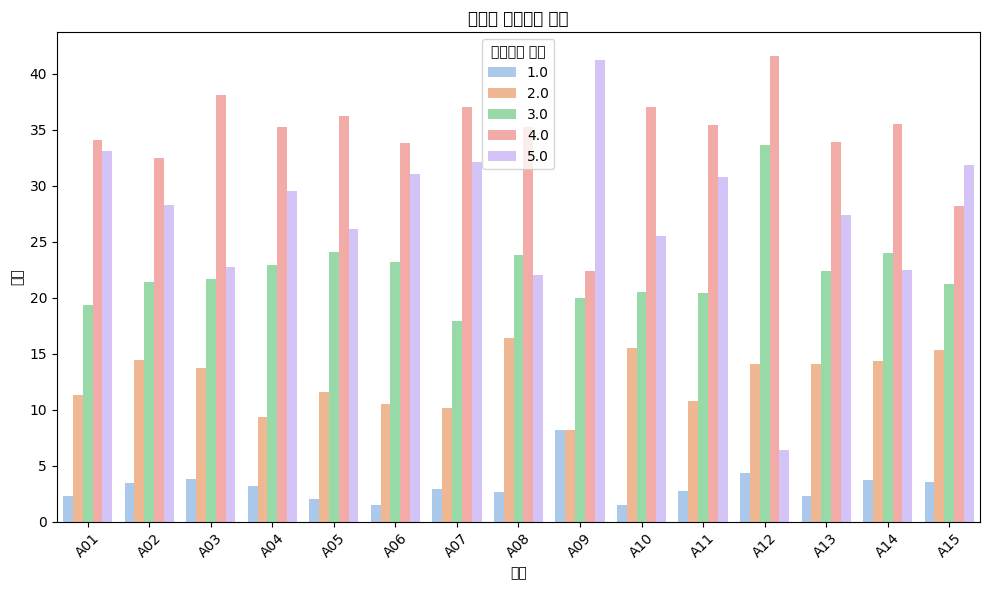

In [ ]:
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=b_count, x='INDUSTRY_CD', y='비율', hue='매출등급 평균', palette='pastel')
plt.title('업종별 매출등급 비율')
plt.xlabel('업종')
plt.ylabel('비율')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()